<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/HDBSCAN_Perbandingan_Distance_Metric.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## HDBSCAN — Perbandingan Distance Metric

Studi ini mengelompokkan dataset URL dengan HDBSCAN. Preprocessing mengikuti notebook DBSCAN referensi, dan seluruh data digunakan tanpa sampling.

**Euclidean distance**

$$
d(x,y)=\sqrt{\sum_i(x_i-y_i)^2}
$$

**Manhattan distance**

$$
d(x,y)=\sum_i\lvert x_i-y_i\rvert
$$

**Cosine distance**

$$
d(x,y)=1-\frac{x\cdot y}{\lVert x\rVert_2\lVert y\rVert_2}
$$

HDBSCAN menggunakan core distance untuk memperhitungkan kepadatan setempat. Untuk `alpha=1`:

$$
d_{mr}(a,b)=\max\left(\operatorname{core}_k(a),\operatorname{core}_k(b),d(a,b)\right)
$$

Hierarki menggunakan tingkat kepadatan berikut; lambda lebih besar berarti ambang jarak lebih kecil:

$$
\lambda=\frac{1}{d_{mr}(a,b)}
$$

HDBSCAN memilih kelompok yang stabil pada hierarki tersebut. Jumlah klaster tidak ditentukan di awal, dan label `-1` menunjukkan noise.

In [ ]:
from IPython import get_ipython
# =======================================================================
# 1. SETUP & IMPORT LIBRARY
# =======================================================================
import importlib.util
from importlib.metadata import version
from pathlib import Path
import gc
import time
import tracemalloc
import json

if importlib.util.find_spec('hdbscan') is None:
    get_ipython().run_line_magic('pip', 'install hdbscan==0.8.44')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from IPython.display import display as ipython_display, HTML
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances, silhouette_score, davies_bouldin_score
from sklearn.metrics.pairwise import paired_euclidean_distances, paired_manhattan_distances, cosine_similarity
from sklearn import config_context
from joblib import Memory
from threadpoolctl import threadpool_limits

get_ipython().run_line_magic('matplotlib', 'inline')
RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'figure.dpi': 120})

# Semua tabel dapat digeser jika lebih lebar daripada area notebook.
def display(*objects):
    for obj in objects:
        if isinstance(obj, pd.DataFrame):
            ipython_display(HTML('<div style="max-width:100%;overflow-x:auto">'
                + obj.to_html(na_rep='N/A', border=0) + '</div>'))
        else:
            ipython_display(obj)

print('hdbscan:', version('hdbscan'), '| scikit-learn:', version('scikit-learn'))

from itertools import combinations


hdbscan: 0.8.44 | scikit-learn: 1.9.1


In [ ]:
# =======================================================================
# 2. DATASET & PREPROCESSING
# =======================================================================
FILE = 'dataset_B_05_2020 (1).csv'
df = pd.read_csv(FILE)

print('Shape dataset:', df.shape)
print('Jumlah data:', df.shape[0])
print('Jumlah kolom:', df.shape[1])
display(df.head(3))

# Metadata dan label asli disimpan terpisah dari fitur clustering.
urls = df['url'].copy()
y_true = df['status'].copy()
labels = y_true.copy()
X = df.drop(columns=['url', 'status']).select_dtypes(include=np.number)
print('Shape fitur numerik:', X.shape)

# Imputasi median, penghapusan fitur konstan, lalu StandardScaler.
print('Missing value sebelum imputasi:', int(X.isna().sum().sum()))
X = X.fillna(X.median())
print('Missing value setelah imputasi:', int(X.isna().sum().sum()))

selector = VarianceThreshold(threshold=0)
X_sel = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()]
removed_features = X.columns[~selector.get_support()]
X_selected = pd.DataFrame(X_sel, columns=selected_features, index=X.index)
print('Fitur konstan yang dihapus:', list(removed_features))
print('Shape setelah seleksi fitur:', X_selected.shape)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_selected)
df_after = pd.DataFrame(X_scaled, columns=selected_features, index=X.index)
print('Shape setelah StandardScaler:', X_scaled.shape)
display(df_after.head(3))


Shape dataset: (11430, 89)
Jumlah data: 11430
Jumlah kolom: 89


,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,ratio_nullHyperlinks,nb_extCSS,ratio_intRedirection,ratio_extRedirection,ratio_intErrors,ratio_extErrors,login_form,external_favicon,links_in_tags,submit_email,ratio_intMedia,ratio_extMedia,sfh,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,0,0,0,0,3,0,1,0,0,0,0,1,0,0,0,1,0.000000,0.0,0,0,0,0,0,3,0,0,0,0,0,0,4,4,3,3,3,11,11,6,5.75,7.0,4.500000,0,0,0,0,0,0,17,0.529412,0.470588,0,0,0,0.875,0,0.5,0,0,80.0,0,100.0,0.0,0,0,0,0.0,0,0,0,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a111aedc8ae390eabcfa130e041a10a4,77,23,1,1,0,0,0,0,0,0,0,0,0,5,0,1,0,0,0,0,0,0,0,0,1,0.220779,0.0,0,0,0,0,0,1,0,0,0,0,1,0,4,4,2,19,2,32,19,32,15.75,19.0,14.666667,0,0,0,0,0,0,30,0.966667,0.033333,0,0,0,0.000,0,0.0,0,0,100.0,0,80.0,20.0,0,0,0,100.0,0,0,0,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duilawyeryork.com/ap/89e6a3b4b063b8d/?cmd=_update&dispatch=89e6a3b4b063b8d1b&locale=_,126,50,1,4,1,0,1,2,0,3,2,0,0,5,0,1,0,0,0,0,0,1,0,0,0,0.150794,0.0,0,0,0,1,0,3,1,0,0,0,1,0,12,2,2,3,2,17,13,17,8.25,8.4,8.142857,0,0,0,0,0,0,4,1.000000,0.000000,0,0,0,0.000,0,0.0,0,0,100.0,0,0.0,0.0,0,0,0,100.0,0,0,0,1,0,0,14,4004,5828815,0,1,0,phishing


Shape fitur numerik: (11430, 87)
Missing value sebelum imputasi: 0
Missing value setelah imputasi: 0
Fitur konstan yang dihapus: ['nb_or', 'ratio_nullHyperlinks', 'ratio_intRedirection', 'ratio_intErrors', 'submit_email', 'sfh']
Shape setelah seleksi fitur: (11430, 81)
Shape setelah StandardScaler: (11430, 81)


,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_eq,nb_underscore,nb_tilde,nb_percent,nb_slash,nb_star,nb_colon,nb_comma,nb_semicolumn,nb_dollar,nb_space,nb_www,nb_com,nb_dslash,http_in_path,https_token,ratio_digits_url,ratio_digits_host,punycode,port,tld_in_path,tld_in_subdomain,abnormal_subdomain,nb_subdomains,prefix_suffix,random_domain,shortening_service,path_extension,nb_redirection,nb_external_redirection,length_words_raw,char_repeat,shortest_words_raw,shortest_word_host,shortest_word_path,longest_words_raw,longest_word_host,longest_word_path,avg_words_raw,avg_word_host,avg_word_path,phish_hints,domain_in_brand,brand_in_subdomain,brand_in_path,suspecious_tld,statistical_report,nb_hyperlinks,ratio_intHyperlinks,ratio_extHyperlinks,nb_extCSS,ratio_extRedirection,ratio_extErrors,login_form,external_favicon,links_in_tags,ratio_intMedia,ratio_extMedia,iframe,popup_window,safe_anchor,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank
0,-0.436327,-0.193964,-0.421020,0.379116,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,-0.081815,-0.083946,-0.685161,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,1.098907,-0.337729,-0.081271,-0.098673,0.798018,-0.594651,-0.267868,-0.01871,-0.04866,-0.264999,-0.229732,-0.148617,1.206090,-0.503825,-0.301425,-0.375276,-0.013229,-0.720143,-0.05621,-0.400711,0.224909,-0.057562,-0.512450,0.200505,-0.198974,0.107876,-0.197666,-0.363968,-0.189497,-0.082894,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.420926,-0.194034,0.605943,-0.284507,2.687711,2.801064,-0.260624,-0.890315,0.674877,1.235290,-0.605350,-0.03625,-0.077932,-0.948614,-0.033744,-0.03744,-0.377549,-1.860473,1.129194,-0.28037,-0.549299,-1.307594,-0.429340,6.978227,0.934264,0.320974
1,0.287067,0.177207,2.375182,-1.081136,-0.477984,-0.142915,-0.387464,-0.197604,-0.293683,-0.295128,-0.081815,-0.083946,0.377443,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,-0.893559,-0.337729,-0.081271,-0.098673,0.798018,1.876053,-0.267868,-0.01871,-0.04866,-0.264999,-0.229732,-0.148617,-1.933425,-0.503825,-0.301425,-0.375276,-0.013229,0.725201,-0.05621,-0.400711,0.224909,-0.509749,3.547014,-0.133086,0.751998,1.730002,0.929003,2.048202,3.164071,1.339666,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.342965,0.967464,-0.760717,-0.284507,-0.596511,-0.399922,-0.260624,-0.890315,1.156557,0.802838,-0.084312,-0.03625,-0.077932,1.610785,-0.033744,-0.03744,-0.377549,0.537498,-0.885587,-0.28037,-0.510022,0.548471,-0.429340,-0.143303,0.934264,-0.467407
2,1.173224,2.682613,2.375182,1.109242,0.001174,-0.142915,2.356473,2.237556,2.711505,1.534217,-0.081815,-0.083946,0.377443,-0.026465,-0.116135,-0.038984,-0.104139,-0.024962,-0.092717,-0.893559,2.300854,-0.081271,-0.098673,-1.253105,1.092856,-0.267868,-0.01871,-0.04866,-0.264999,4.352889,-0.148617,1.206090,1.984817,-0.301425,-0.375276,-0.013229,0.725201,-0.05621,1.035010,-0.194490,-0.509749,-0.512450,-0.133086,0.072732,0.513407,0.279002,0.239075,0.201752,0.426829,-0.388973,-0.341057,-0.064257,-0.070168,-0.13514,-0.180392,-0.498886,1.056008,-0.864902,-0.284507,-0.596511,-0.399922,-0.260624,-0.890315,1.156557,-0.926971,-0.605350,-0.03625,-0.077932,1.610785,-0.033744,-0.03744,-0.377549,0.537498,-0.885587,-0.28037,-0.587348,-0.018839,2.491612,-0.143303,0.934264,-1.255788


### Bukti kalkulasi ketiga metrik jarak

P0/P1/P2 memakai semua fitur hasil StandardScaler. Rincian P0–P1 menunjukkan kontribusi setiap fitur: kuadrat selisih untuk Euclidean, selisih absolut untuk Manhattan, dan perkalian vektor L2 untuk cosine similarity. Cosine distance = 1 − similarity. Agregat diperiksa terhadap hasil library. Normalisasi L2 di tabel cosine hanya untuk menjelaskan rumus.

In [ ]:
DISTANCE_METRICS = ['euclidean', 'manhattan', 'cosine']
STUDY_NAME = 'perbandingan'


# =======================================================================
# 3. BUKTI DISTANCE METRIC DENGAN LIBRARY
# =======================================================================
EXAMPLE_NODES = [0, 1, 2]
pair_rows = []
feature_tables = {}
for a, b in combinations(EXAMPLE_NODES, 2):
    row = {'Pasangan': f'P{a} - P{b}'}
    for metric in DISTANCE_METRICS:
        row[metric] = pairwise_distances(X_scaled[a:a+1], X_scaled[b:b+1], metric=metric)[0, 0]
    pair_rows.append(row)
pair_distance_df = pd.DataFrame(pair_rows)
display(pair_distance_df.round(8))

a, b = EXAMPLE_NODES[:2]
x, y = X_scaled[a], X_scaled[b]
for metric in DISTANCE_METRICS:
    table = pd.DataFrame({'Fitur': selected_features, f'P{a}': x, f'P{b}': y})
    if metric == 'euclidean':
        per_feature = paired_euclidean_distances(x[:, None], y[:, None])
        table['Jarak per fitur'] = per_feature
        table['Kontribusi kuadrat'] = per_feature ** 2
        total = np.sqrt(table['Kontribusi kuadrat'].sum())
    elif metric == 'manhattan':
        table['Kontribusi jarak'] = paired_manhattan_distances(x[:, None], y[:, None])
        total = table['Kontribusi jarak'].sum()
    else:
        table[f'P{a} setelah L2'] = normalize(x[None, :])[0]
        table[f'P{b} setelah L2'] = normalize(y[None, :])[0]
        table['Kontribusi similarity'] = table[f'P{a} setelah L2'] * table[f'P{b} setelah L2']
        similarity = cosine_similarity(x[None, :], y[None, :])[0, 0]
        np.testing.assert_allclose(table['Kontribusi similarity'].sum(), similarity, atol=1e-10)
        total = 1 - table['Kontribusi similarity'].sum()
    builtin = pair_distance_df.iloc[0][metric]
    np.testing.assert_allclose(total, builtin, rtol=1e-8, atol=1e-10)
    print(f'P{a} - P{b}, {metric}: agregat fitur = {total:.8f}; library = {builtin:.8f}; sesuai.')
    display(HTML(f'<details><summary>Rincian {len(table)} fitur — {metric}, P{a} ke P{b}</summary>'
        '<div style="overflow-x:auto">' + table.to_html(index=False, float_format=lambda v: f'{v:.8f}')
        + '</div></details>'))
    feature_tables[metric] = table


,Pasangan,euclidean,manhattan,cosine
0,P0 - P1,13.059100,58.498862,1.162640
1,P0 - P2,14.384229,73.599151,1.174413
2,P1 - P2,11.554632,52.856607,0.863533


P0 - P1, euclidean: agregat fitur = 13.05909953; library = 13.05909953; sesuai.


Fitur,P0,P1,Jarak per fitur,Kontribusi kuadrat
length_url,-0.43632748,0.28706655,0.72339403,0.52329893
length_hostname,-0.19396372,0.17720743,0.37117115,0.13776802
ip,-0.42102044,2.37518157,2.79620202,7.81874572
nb_dots,0.37911625,-1.08113606,1.46025231,2.13233682
nb_hyphens,-0.47798396,-0.47798396,0.00000000,0.00000000
nb_at,-0.14291457,-0.14291457,0.00000000,0.00000000
nb_qm,-0.38746409,-0.38746409,0.00000000,0.00000000
nb_and,-0.19760370,-0.19760370,0.00000000,0.00000000
nb_eq,-0.29368288,-0.29368288,0.00000000,0.00000000
nb_underscore,-0.29512783,-0.29512783,0.00000000,0.00000000


P0 - P1, manhattan: agregat fitur = 58.49886247; library = 58.49886247; sesuai.


Fitur,P0,P1,Kontribusi jarak
length_url,-0.43632748,0.28706655,0.72339403
length_hostname,-0.19396372,0.17720743,0.37117115
ip,-0.42102044,2.37518157,2.79620202
nb_dots,0.37911625,-1.08113606,1.46025231
nb_hyphens,-0.47798396,-0.47798396,0.00000000
nb_at,-0.14291457,-0.14291457,0.00000000
nb_qm,-0.38746409,-0.38746409,0.00000000
nb_and,-0.19760370,-0.19760370,0.00000000
nb_eq,-0.29368288,-0.29368288,0.00000000
nb_underscore,-0.29512783,-0.29512783,0.00000000


P0 - P1, cosine: agregat fitur = 1.16263980; library = 1.16263980; sesuai.


Fitur,P0,P1,P0 setelah L2,P1 setelah L2,Kontribusi similarity
length_url,-0.43632748,0.28706655,-0.04747300,0.03632872,-0.00172463
length_hostname,-0.19396372,0.17720743,-0.02110351,0.02242588,-0.00047326
ip,-0.42102044,2.37518157,-0.04580758,0.30058296,-0.01376898
nb_dots,0.37911625,-1.08113606,0.04124834,-0.13681947,-0.00564358
nb_hyphens,-0.47798396,-0.47798396,-0.05200528,-0.06048962,0.00314578
nb_at,-0.14291457,-0.14291457,-0.01554929,-0.01808606,0.00028123
nb_qm,-0.38746409,-0.38746409,-0.04215660,-0.04903419,0.00206711
nb_and,-0.19760370,-0.19760370,-0.02149954,-0.02500706,0.00053764
nb_eq,-0.29368288,-0.29368288,-0.03195308,-0.03716603,0.00118757
nb_underscore,-0.29512783,-0.29512783,-0.03211029,-0.03734889,0.00119928


### Parameter bersama untuk perbandingan

`min_cluster_size` adalah ukuran minimum kelompok yang dianggap klaster. `min_samples` menentukan tetangga untuk memperkirakan kepadatan. Keduanya ditetapkan terpisah dan dipakai oleh semua metrik.

Notebook ini memakai `min_cluster_size=20` dan `min_samples=5`. Parameter ditetapkan sekali pada cell berikut, kemudian digunakan oleh fit, evaluasi, uji skala, potongan tree, grafik, dan tabel. Hanya distance metric yang berubah. Pencarian parameter tersedia di notebook individual.


In [ ]:
# =======================================================================
# 4. PARAMETER & FUNGSI EVALUASI
# =======================================================================
MIN_CLUSTER_SIZE = 20
MIN_SAMPLES = 5
print("Parameter bersama:", MIN_CLUSTER_SIZE, MIN_SAMPLES)

# Jalur generic mendukung cosine dan digunakan untuk ketiga metrik.
MODEL_OPTIONS = dict(algorithm='generic', cluster_selection_method='eom',
    alpha=1.0, cluster_selection_epsilon=0.0, allow_single_cluster=False,
    approx_min_span_tree=False, core_dist_n_jobs=1)

# Cache hanya untuk uji skala berulang; benchmark final tidak memakai cache.
cache = Memory('.hdbscan_cache_simple', verbose=0)
output_dir = Path('hasil_hdbscan') / STUDY_NAME
output_dir.mkdir(parents=True, exist_ok=True)
assert np.isfinite(X_scaled).all()
if 'cosine' in DISTANCE_METRICS:
    assert np.all(np.linalg.norm(X_scaled, axis=1) > 0), 'Cosine memerlukan vektor nonzero.'

def buat_model(metric, min_cluster_size, min_samples, use_cache=False):
    return hdbscan.HDBSCAN(metric=metric, min_cluster_size=int(min_cluster_size),
        min_samples=int(min_samples), memory=cache if use_cache else Memory(None), **MODEL_OPTIONS)

def evaluasi(X_data, cluster_labels, metric):
    mask = cluster_labels != -1
    n_clusters = len(np.unique(cluster_labels[mask]))
    silhouette, dbi = np.nan, np.nan
    if 2 <= n_clusters < int(mask.sum()):
        with threadpool_limits(limits=1), config_context(working_memory=128):
            silhouette = float(silhouette_score(X_data[mask], cluster_labels[mask], metric=metric))
            # DBI sklearn memakai Euclidean; basis evaluasinya sama untuk semua model.
            dbi = float(davies_bouldin_score(X_data[mask], cluster_labels[mask]))
    return {'Jumlah Klaster': n_clusters, 'Non-noise': int(mask.sum()),
        'Noise': int((~mask).sum()), 'Noise (%)': 100 * (~mask).mean(),
        'Silhouette Score': silhouette, 'DBI (Euclidean)': dbi}


Parameter bersama: 20 5


### Hasil klaster dan evaluasi

Silhouette lebih tinggi lebih baik dan dihitung dengan metrik yang sama seperti fit. DBI lebih rendah lebih baik; fungsi DBI sklearn memakai Euclidean untuk semua model, sehingga kolom diberi nama **DBI (Euclidean)**. Keduanya memakai seluruh titik non-noise dan menjadi N/A jika jumlah klaster tidak memenuhi syarat.

Waktu dan puncak alokasi `tracemalloc` diukur selama fit final tanpa cache, termasuk perhitungan jarak. Evaluasi dan grafik berada di luar pengukuran. Memori terlacak bukan total RSS proses. Semua metrik memakai algoritma generic dan satu thread.

In [ ]:
# =======================================================================
# 6. FIT FINAL & TABEL HASIL
# =======================================================================
models_by_metric, cluster_labels_by_metric = {}, {}
results = []
for metric in DISTANCE_METRICS:
    print(f'Fit final {metric}', flush=True)
    gc.collect()
    model = buat_model(metric, MIN_CLUSTER_SIZE, MIN_SAMPLES)
    with threadpool_limits(limits=1):
        tracemalloc.start()
        start = time.perf_counter()
        try:
            cluster_labels = model.fit_predict(X_scaled)
            seconds = time.perf_counter() - start
            _, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()
    assert model.min_cluster_size == MIN_CLUSTER_SIZE and model.min_samples == MIN_SAMPLES
    np.testing.assert_array_equal(cluster_labels, model.labels_)
    results.append({'Distance Metric': metric.title(), 'MIN_CLUSTER_SIZE': model.min_cluster_size,
        'MIN_SAMPLES': model.min_samples, 'Algorithm': model.algorithm,
        **evaluasi(X_scaled, cluster_labels, metric),
        'Waktu Eksekusi (detik)': seconds, 'Penggunaan Memori (MiB)': peak / 1024**2})
    models_by_metric[metric] = model
    cluster_labels_by_metric[metric] = cluster_labels.copy()
comparison_df = pd.DataFrame(results)
display(comparison_df.round(5))
assert comparison_df['MIN_CLUSTER_SIZE'].nunique() == 1
assert comparison_df['MIN_SAMPLES'].nunique() == 1

for metric, cluster_labels in cluster_labels_by_metric.items():
    counts = pd.Series(cluster_labels).value_counts().sort_index().rename_axis('Cluster').reset_index(name='Jumlah Data')
    counts['Persentase (%)'] = 100 * counts['Jumlah Data'] / len(cluster_labels)
    print(f'Distribusi {metric}; label -1 adalah noise:')
    display(counts.round(2))
    counts.to_csv(output_dir / f'{metric}_distribusi_klaster.csv', index=False)


Fit final euclidean


Fit final manhattan


Fit final cosine


,Distance Metric,MIN_CLUSTER_SIZE,MIN_SAMPLES,Algorithm,Jumlah Klaster,Non-noise,Noise,Noise (%),Silhouette Score,DBI (Euclidean),Waktu Eksekusi (detik),Penggunaan Memori (MiB)
0,Euclidean,20,5,generic,72,3368,8062,70.53368,0.35214,1.03358,5.66485,1993.58383
1,Manhattan,20,5,generic,57,2584,8846,77.39283,0.49514,0.98664,8.89679,1993.57947
2,Cosine,20,5,generic,80,3259,8171,71.48731,0.54928,1.17965,6.35012,2367.27109


Distribusi euclidean; label -1 adalah noise:


,Cluster,Jumlah Data,Persentase (%)
0,-1,8062,70.53
1,0,26,0.23
2,1,27,0.24
3,2,43,0.38
4,3,34,0.30
5,4,68,0.59
6,5,66,0.58
7,6,52,0.45
8,7,53,0.46
9,8,23,0.20


Distribusi manhattan; label -1 adalah noise:


,Cluster,Jumlah Data,Persentase (%)
0,-1,8846,77.39
1,0,85,0.74
2,1,22,0.19
3,2,59,0.52
4,3,29,0.25
5,4,22,0.19
6,5,22,0.19
7,6,53,0.46
8,7,38,0.33
9,8,24,0.21


Distribusi cosine; label -1 adalah noise:


,Cluster,Jumlah Data,Persentase (%)
0,-1,8171,71.49
1,0,27,0.24
2,1,68,0.59
3,2,66,0.58
4,3,26,0.23
5,4,53,0.46
6,5,39,0.34
7,6,24,0.21
8,7,29,0.25
9,8,38,0.33


### Core distance dan mutual reachability

Pada paket `hdbscan` yang dipakai di sini, `min_samples=k` berarti k tetangga selain node sendiri. Tetangga dihitung terhadap seluruh dataset. Jarak ke tetangga ke-k menjadi core distance. Mutual reachability mengambil nilai terbesar dari dua core distance dan jarak asli.

Tabel berikut menghubungkan P0/P1/P2 dengan label hasil model. Label klaster ditentukan dari keseluruhan hierarki, bukan dari satu pasangan jarak saja. Kekuatan keanggotaan bukan probabilitas phishing.

In [ ]:
# =======================================================================
# 7. CONTOH CORE DISTANCE & MUTUAL REACHABILITY
# =======================================================================
core_tables, reachability_tables = {}, {}
for metric in DISTANCE_METRICS:
    model = models_by_metric[metric]
    with threadpool_limits(limits=1):
        D = pairwise_distances(X_scaled[EXAMPLE_NODES], X_scaled, metric=metric)
    cores, neighbors, node_rows = {}, [], []
    for row, node in enumerate(EXAMPLE_NODES):
        D[row, node] = 0.0
        other = np.delete(np.arange(len(X_scaled)), node)
        order = other[np.argsort(D[row, other], kind='stable')[:model.min_samples]]
        cores[node] = float(D[row, order[-1]])
        np.testing.assert_allclose(cores[node], np.partition(D[row], model.min_samples)[model.min_samples], atol=1e-10)
        for rank, neighbor in enumerate(order, start=1):
            neighbors.append({'Node': f'P{node}', 'Urutan selain sendiri': rank,
                'Tetangga': f'P{neighbor}', 'Jarak': D[row, neighbor]})
        node_rows.append({'Node': f'P{node}', 'Core Distance': cores[node],
            'Label HDBSCAN': int(model.labels_[node]), 'Kekuatan Keanggotaan': model.probabilities_[node]})
    print(f'Core distance {metric}: tetangga ke-{model.min_samples} selain sendiri.')
    core_tables[metric] = pd.DataFrame(neighbors)
    display(core_tables[metric].round(8))
    display(pd.DataFrame(node_rows).round(8))
    pairs = []
    for pair_index, (a, b) in enumerate(combinations(EXAMPLE_NODES, 2)):
        raw = float(pair_distance_df.iloc[pair_index][metric])
        np.testing.assert_allclose(raw, D[EXAMPLE_NODES.index(a), b], atol=1e-10)
        pairs.append({'Pasangan': f'P{a} - P{b}', 'Jarak Asli': raw,
            'Core A': cores[a], 'Core B': cores[b], 'Mutual Reachability': max(raw, cores[a], cores[b])})
    reachability_tables[metric] = pd.DataFrame(pairs)
    display(reachability_tables[metric].round(8))


Core distance euclidean: tetangga ke-5 selain sendiri.


,Node,Urutan selain sendiri,Tetangga,Jarak
0,P0,1,P9333,5.609147
1,P0,2,P4886,5.697852
2,P0,3,P2872,5.998942
3,P0,4,P5912,6.228467
4,P0,5,P2810,6.269320
5,P1,1,P1651,0.145341
6,P1,2,P766,0.209703
7,P1,3,P3406,0.436194
8,P1,4,P289,0.443867
9,P1,5,P2093,0.443867


,Node,Core Distance,Label HDBSCAN,Kekuatan Keanggotaan
0,P0,6.269320,13,0.431253
1,P1,0.443867,34,0.473483
2,P2,0.447153,24,1.000000


,Pasangan,Jarak Asli,Core A,Core B,Mutual Reachability
0,P0 - P1,13.059100,6.269320,0.443867,13.059100
1,P0 - P2,14.384229,6.269320,0.447153,14.384229
2,P1 - P2,11.554632,0.443867,0.447153,11.554632


Core distance manhattan: tetangga ke-5 selain sendiri.


...

,Pasangan,Jarak Asli,Core A,Core B,Mutual Reachability
0,P0 - P1,58.498862,22.488663,0.564735,58.498862
1,P0 - P2,73.599151,22.488663,0.815449,73.599151
2,P1 - P2,52.856607,0.564735,0.815449,52.856607


Core distance cosine: tetangga ke-5 selain sendiri.


,Node,Urutan selain sendiri,Tetangga,Jarak
0,P0,1,P9333,0.191710
1,P0,2,P4886,0.198960
2,P0,3,P2872,0.231237
3,P0,4,P5912,0.249688
4,P0,5,P2810,0.251069
5,P1,1,P1651,0.000161
6,P1,2,P766,0.000351
7,P1,3,P3406,0.001400
8,P1,4,P2093,0.001561
9,P1,5,P289,0.001575


,Node,Core Distance,Label HDBSCAN,Kekuatan Keanggotaan
0,P0,0.251069,15,0.211961
1,P1,0.001575,37,0.216727
2,P2,0.001090,5,1.000000


,Pasangan,Jarak Asli,Core A,Core B,Mutual Reachability
0,P0 - P1,1.162640,0.251069,0.001575,1.162640
1,P0 - P2,1.174413,0.251069,0.001090,1.174413
2,P1 - P2,0.863533,0.001575,0.001090,0.863533


### Visualisasi PCA

PCA hanya menghasilkan koordinat gambar. Clustering dan evaluasi tetap memakai seluruh fitur setelah StandardScaler. Semua metrik digambar pada koordinat yang sama, dan noise ditandai hitam. Warna atau nomor klaster antar-metrik tidak otomatis menunjukkan kelompok yang sama.

Variansi yang dijelaskan PC1 + PC2: 15.51%


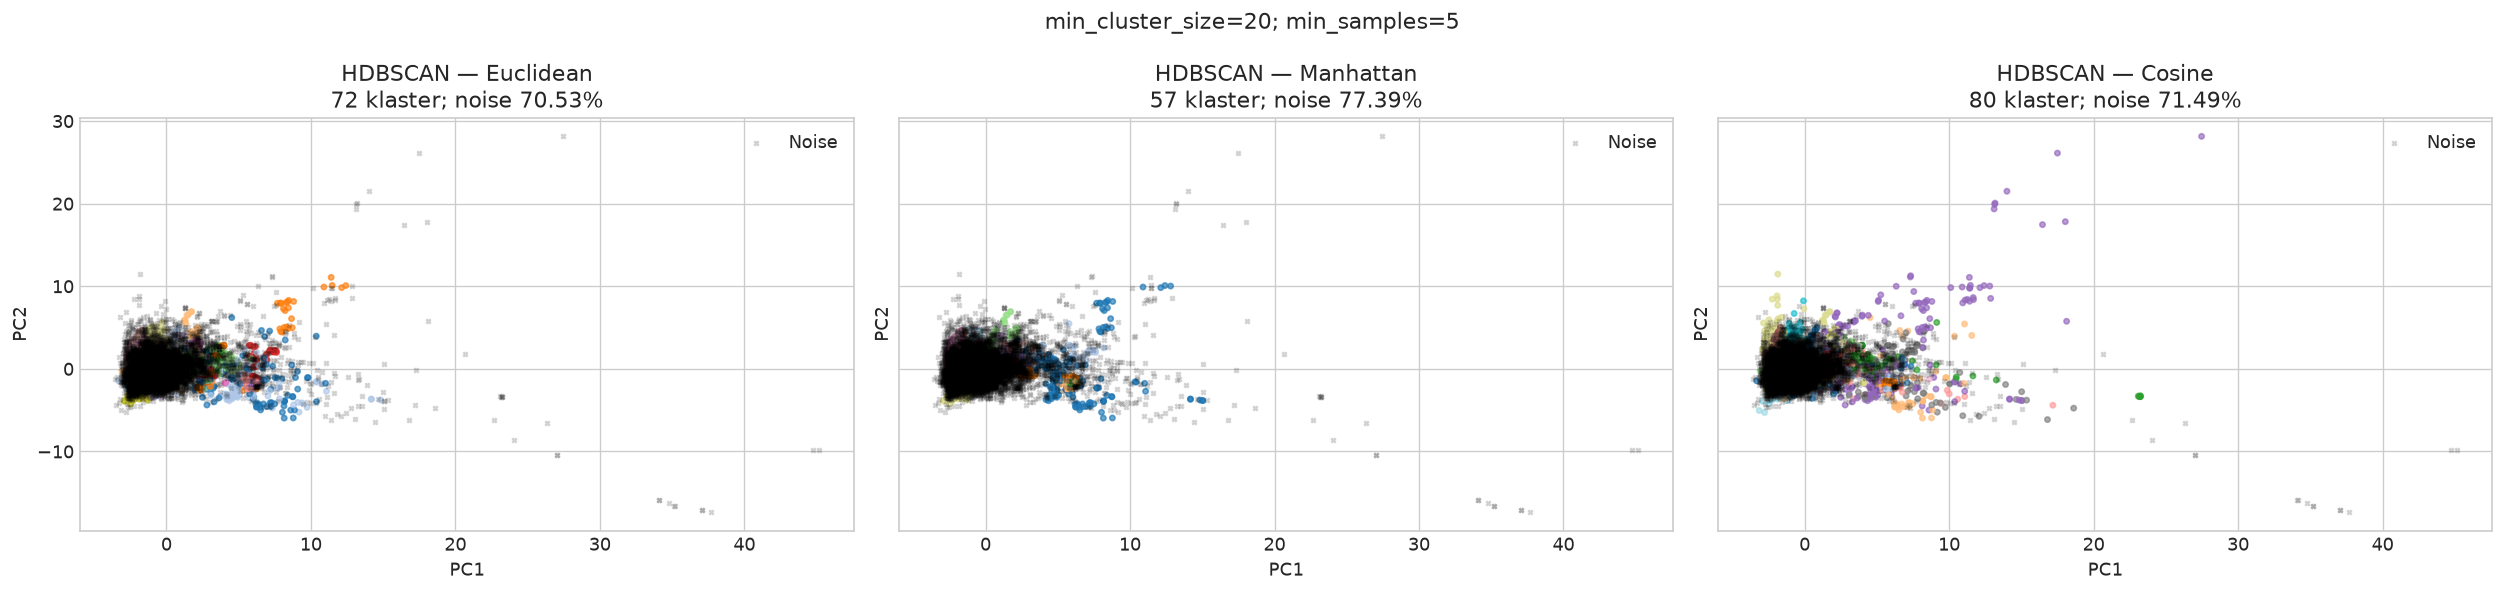

In [ ]:
# =======================================================================
# 8. VISUALISASI PCA: KOORDINAT YANG SAMA UNTUK SEMUA METRIK
# =======================================================================
pca = PCA(n_components=2, svd_solver='full', random_state=RANDOM_STATE)
with threadpool_limits(limits=1):
    X_pca = pca.fit_transform(X_scaled)
print(f'Variansi yang dijelaskan PC1 + PC2: {pca.explained_variance_ratio_.sum():.2%}')

def plot_cluster(ax, coordinates, cluster_labels, title):
    mask = cluster_labels != -1
    if mask.any():
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], c=cluster_labels[mask], cmap='tab20', s=10, alpha=0.65)
    if (~mask).any():
        ax.scatter(coordinates[~mask, 0], coordinates[~mask, 1], color='black', marker='x', s=7, alpha=0.18, label='Noise')
        ax.legend()
    ax.set(title=title, xlabel='PC1', ylabel='PC2')

fig, axes = plt.subplots(1, len(DISTANCE_METRICS), figsize=(7 * len(DISTANCE_METRICS), 5), squeeze=False, sharex=True, sharey=True)
for ax, metric in zip(axes.ravel(), DISTANCE_METRICS):
    row = comparison_df.loc[comparison_df['Distance Metric'].str.lower() == metric].iloc[0]
    plot_cluster(ax, X_pca, cluster_labels_by_metric[metric],
        f"HDBSCAN — {metric.title()}\n{int(row['Jumlah Klaster'])} klaster; noise {row['Noise (%)']:.2f}%")
fig.suptitle(f'min_cluster_size={MIN_CLUSTER_SIZE}; min_samples={MIN_SAMPLES}')
plt.tight_layout()
plt.savefig(output_dir / 'pca_klaster.png', bbox_inches='tight')
plt.show()


### Pengaruh skala pada HDBSCAN

Coba skala 1, 0,5, dan 3 dengan parameter tetap. Perkalian dilakukan setelah preprocessing pada semua fitur; scaler tidak dilatih ulang. Model dilatih pada `X_scaled × scale` dan digambar pada `X_pca × scale`.

Perhatikan jumlah klaster, noise, dan pola titiknya. Penskalaan seragam menjaga struktur relatif jarak Euclidean/Manhattan dan tidak mengubah arah vektor cosine; hasil HDBSCAN umumnya tetap, dengan kemungkinan perbedaan kecil akibat presisi numerik. Ini berbeda dari mengubah skala hanya beberapa fitur.

Uji skala euclidean: 1


Uji skala euclidean: 0.5


Uji skala euclidean: 3


Uji skala manhattan: 1


Uji skala manhattan: 0.5


Uji skala manhattan: 3


Uji skala cosine: 1


Uji skala cosine: 0.5


Uji skala cosine: 3


,Distance Metric,Scale,MIN_CLUSTER_SIZE,MIN_SAMPLES,Jumlah Klaster,Noise,Noise (%)
0,euclidean,1.0,20,5,72,8062,70.5337
1,euclidean,0.5,20,5,72,8062,70.5337
2,euclidean,3.0,20,5,72,8062,70.5337
3,manhattan,1.0,20,5,57,8846,77.3928
4,manhattan,0.5,20,5,57,8846,77.3928
5,manhattan,3.0,20,5,57,8846,77.3928
6,cosine,1.0,20,5,80,8171,71.4873
7,cosine,0.5,20,5,80,8171,71.4873
8,cosine,3.0,20,5,80,8171,71.4873


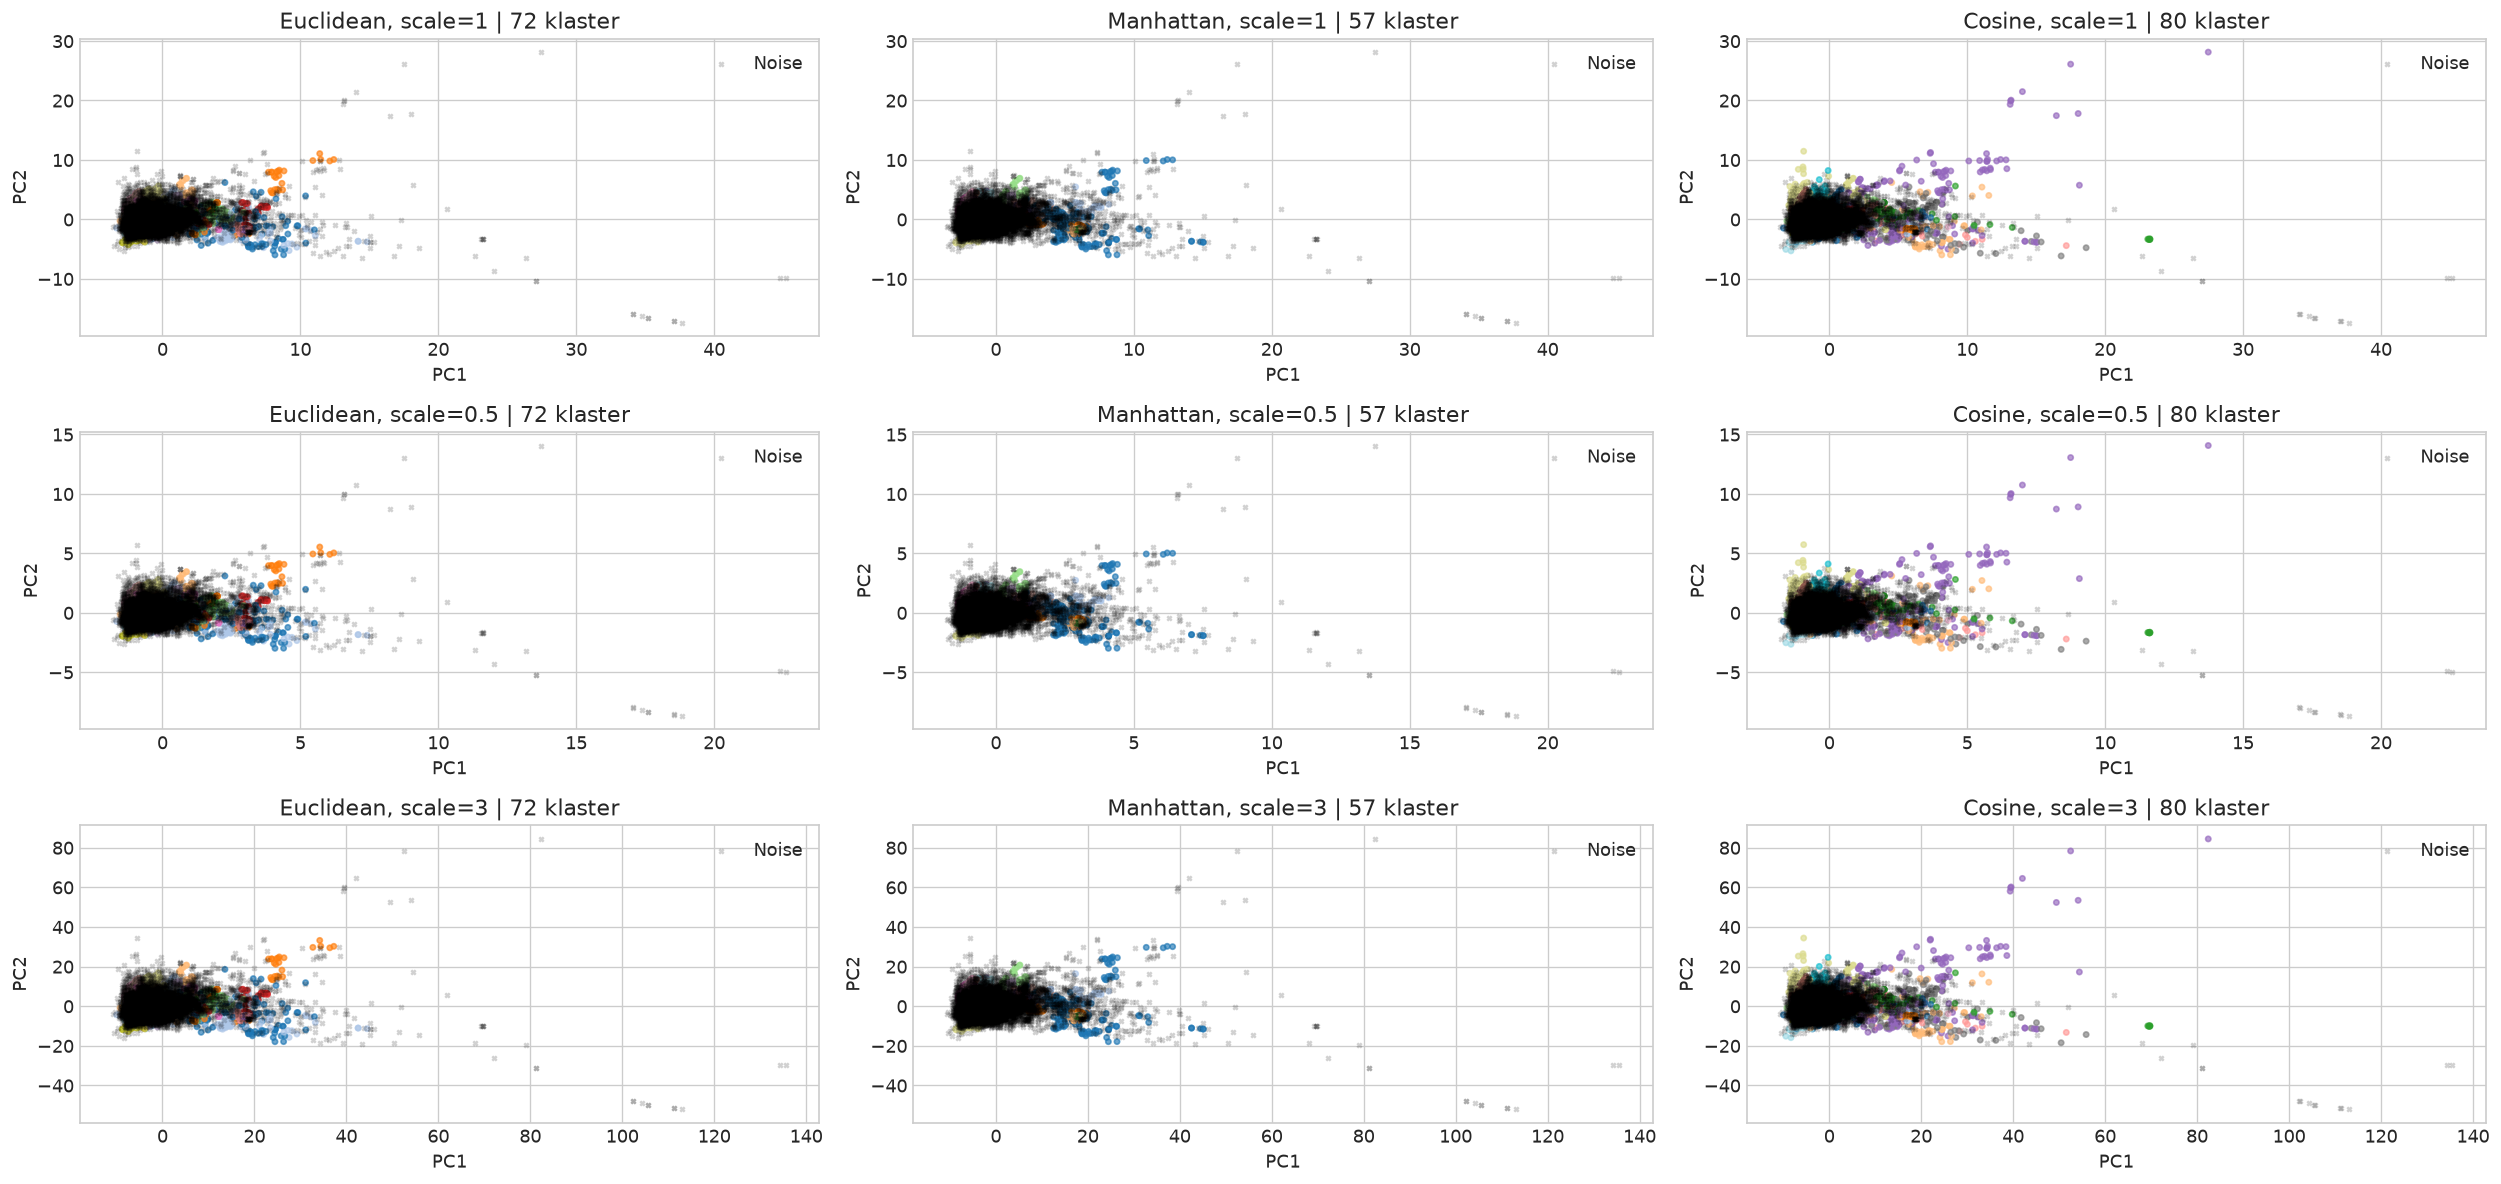

In [ ]:
# =======================================================================
# 9. PENGARUH SKALA SERAGAM
# =======================================================================
SCALES = [1, 0.5, 3]
scale_rows = []
scale_models_by_metric = {}
fig, axes = plt.subplots(len(SCALES), len(DISTANCE_METRICS), figsize=(7 * len(DISTANCE_METRICS), 10), squeeze=False)
for column, metric in enumerate(DISTANCE_METRICS):
    base_model = models_by_metric[metric]
    for row, scale in enumerate(SCALES):
        print(f'Uji skala {metric}: {scale}', flush=True)
        if scale == 1:
            model = models_by_metric[metric]
        else:
            with threadpool_limits(limits=1):
                model = buat_model(metric, base_model.min_cluster_size, base_model.min_samples, use_cache=True).fit(X_scaled * scale)
        scale_models_by_metric[(metric, scale)] = model
        mask = model.labels_ != -1
        n_clusters = len(np.unique(model.labels_[mask]))
        scale_rows.append({'Distance Metric': metric, 'Scale': scale,
            'MIN_CLUSTER_SIZE': model.min_cluster_size, 'MIN_SAMPLES': model.min_samples,
            'Jumlah Klaster': n_clusters, 'Noise': int((~mask).sum()), 'Noise (%)': 100 * (~mask).mean()})
        plot_cluster(axes[row, column], X_pca * scale, model.labels_,
            f'{metric.title()}, scale={scale} | {n_clusters} klaster')
scale_df = pd.DataFrame(scale_rows)
display(scale_df.round(4))
plt.tight_layout()
plt.savefig(output_dir / 'uji_skala.png', bbox_inches='tight')
plt.show()


### Percobaan cut_distance

`dbscan_clustering()` memotong tree pada satu jarak tertentu dan menghasilkan DBSCAN*, yang tidak memasukkan border point seperti DBSCAN biasa. Percobaan memakai cut_distance 0,1; 0,5; dan 1,0. Hasil potongan ditampilkan terpisah dari hasil utama HDBSCAN.

Angka jarak yang sama mempunyai makna berbeda pada setiap metrik. Pada fitur dataset URL, potongan kecil dapat menghasilkan seluruhnya noise. Ukuran titik dibuat tetap karena `probabilities_` model HDBSCAN bukan kekuatan keanggotaan untuk label potongan baru.

,Distance Metric,Cut Distance,MIN_CLUSTER_SIZE,MIN_SAMPLES,Jumlah Klaster,Noise,Noise (%)
0,euclidean,0.1,20,5,0,11430,100.0000
1,euclidean,0.5,20,5,5,11246,98.3902
2,euclidean,1.0,20,5,10,11055,96.7192
3,manhattan,0.1,20,5,0,11430,100.0000
4,manhattan,0.5,20,5,3,11340,99.2126
5,manhattan,1.0,20,5,8,11161,97.6465
6,cosine,0.1,20,5,39,9513,83.2283
7,cosine,0.5,20,5,2,41,0.3587
8,cosine,1.0,20,5,1,0,0.0000


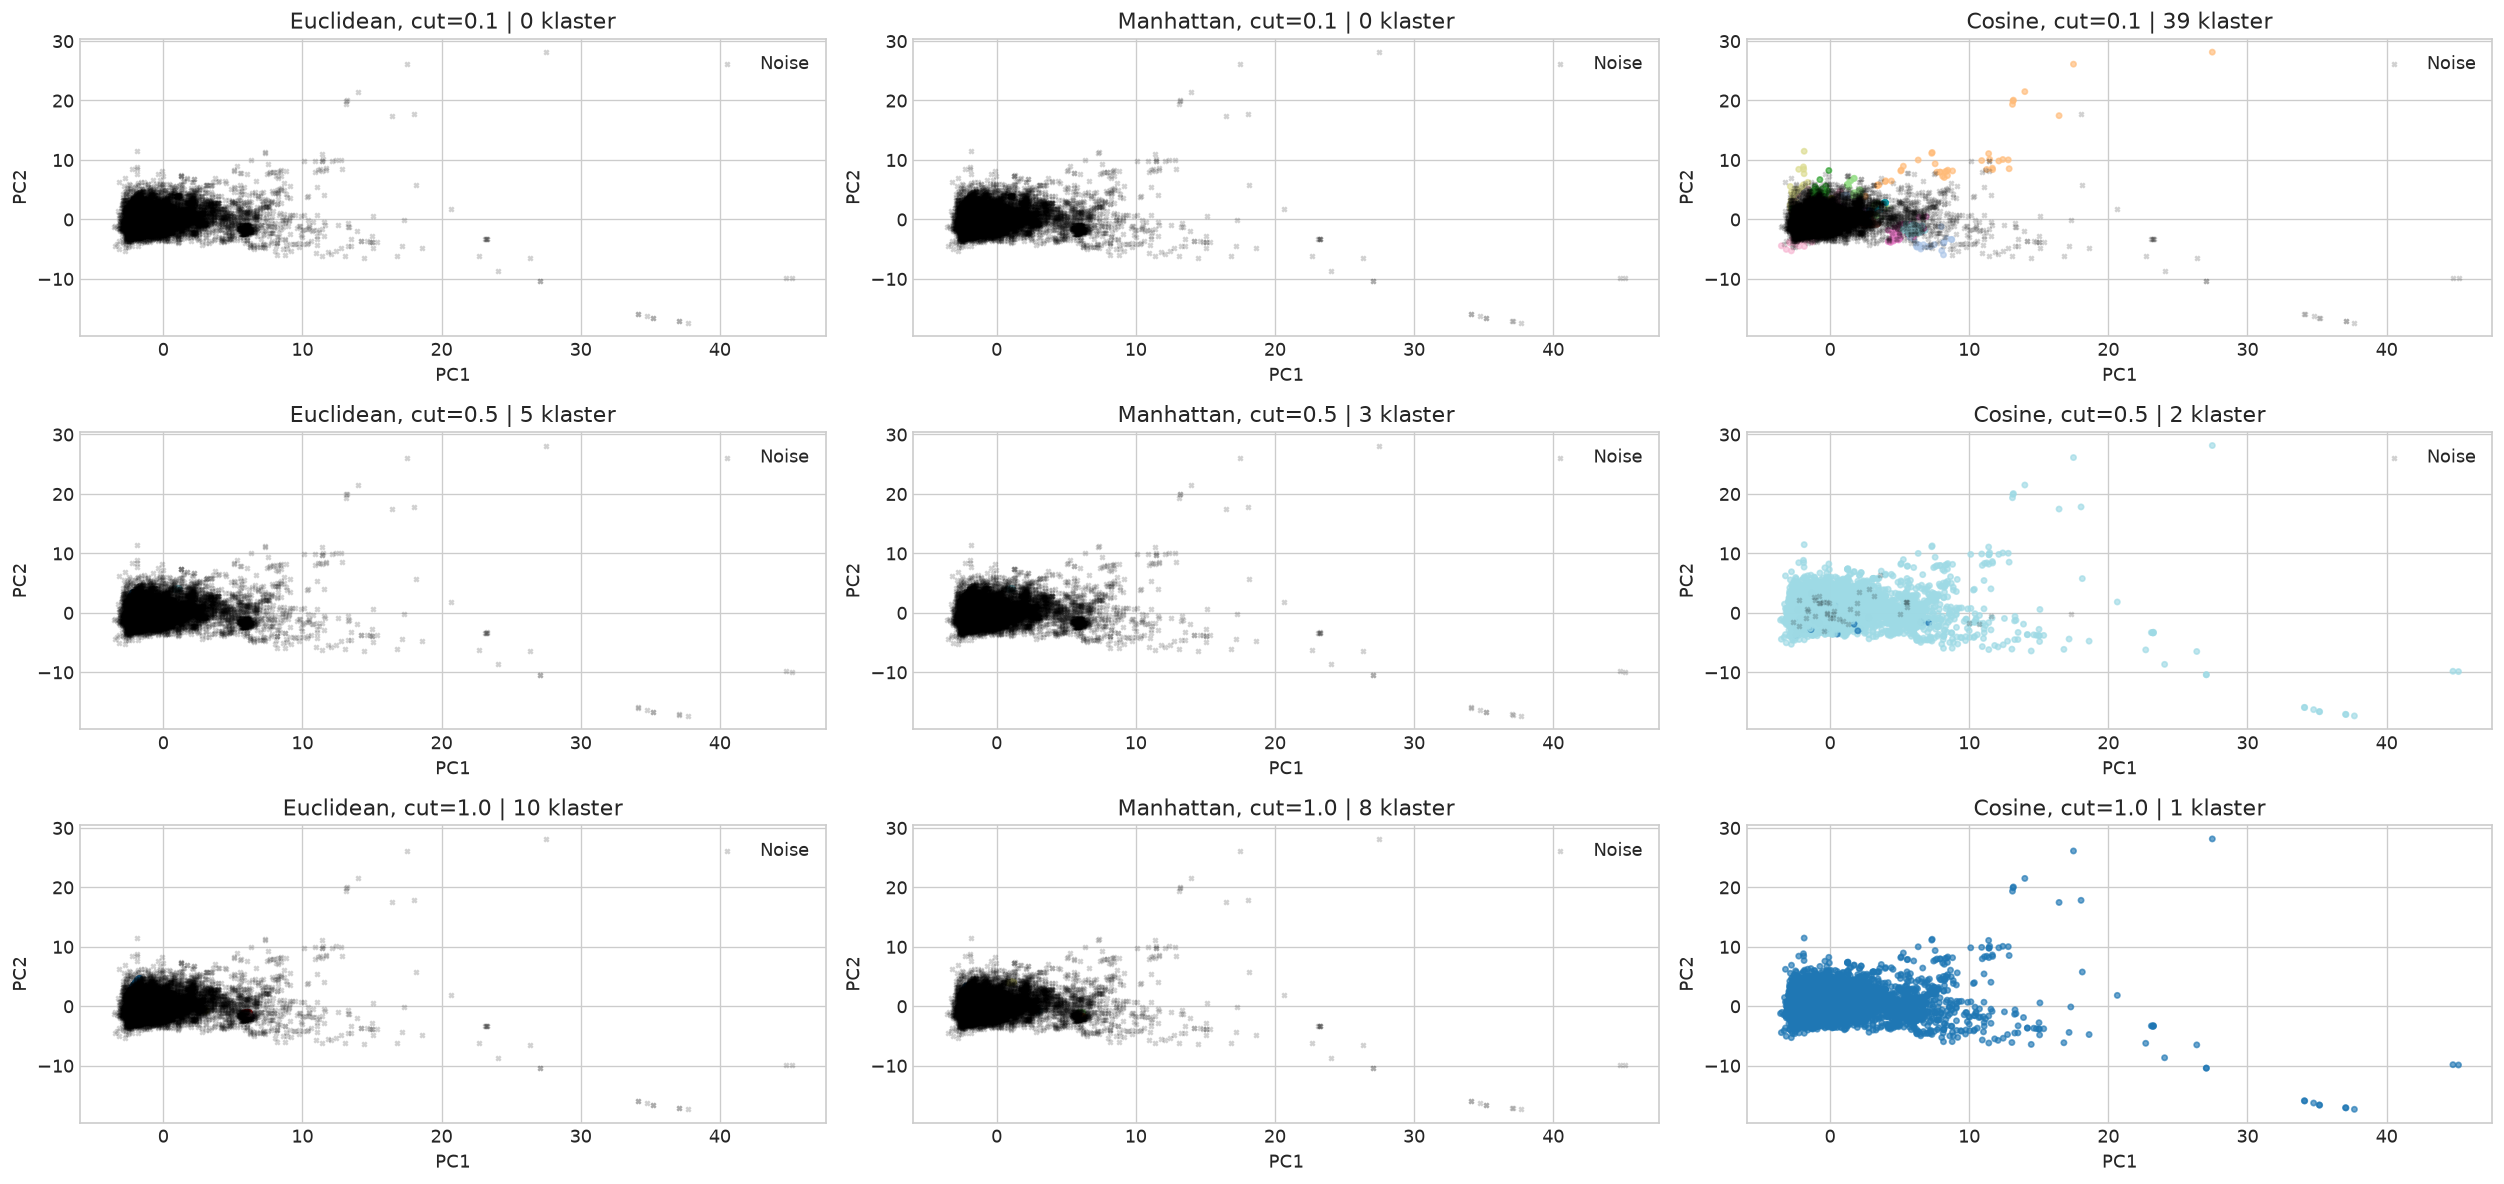

In [ ]:
# =======================================================================
# 10. CUT_DISTANCE DARI TREE HDBSCAN
# =======================================================================
CUT_DISTANCES = [0.1, 0.5, 1.0]
cut_rows = []
cut_labels_by_metric = {}
fig, axes = plt.subplots(len(CUT_DISTANCES), len(DISTANCE_METRICS), figsize=(7 * len(DISTANCE_METRICS), 10), squeeze=False)
for column, metric in enumerate(DISTANCE_METRICS):
    base_model = models_by_metric[metric]
    for row, cut in enumerate(CUT_DISTANCES):
        cut_labels = base_model.dbscan_clustering(cut_distance=cut, min_cluster_size=base_model.min_cluster_size)
        cut_labels_by_metric[(metric, cut)] = cut_labels.copy()
        mask = cut_labels != -1
        n_clusters = len(np.unique(cut_labels[mask]))
        cut_rows.append({'Distance Metric': metric, 'Cut Distance': cut,
            'MIN_CLUSTER_SIZE': base_model.min_cluster_size, 'MIN_SAMPLES': base_model.min_samples,
            'Jumlah Klaster': n_clusters, 'Noise': int((~mask).sum()), 'Noise (%)': 100 * (~mask).mean()})
        # Ukuran titik tetap: probabilities_ HDBSCAN tidak berlaku untuk label potongan DBSCAN*.
        plot_cluster(axes[row, column], X_pca, cut_labels, f'{metric.title()}, cut={cut} | {n_clusters} klaster')
cut_df = pd.DataFrame(cut_rows)
display(cut_df.round(4))
plt.tight_layout()
plt.savefig(output_dir / 'cut_distance.png', bbox_inches='tight')
plt.show()


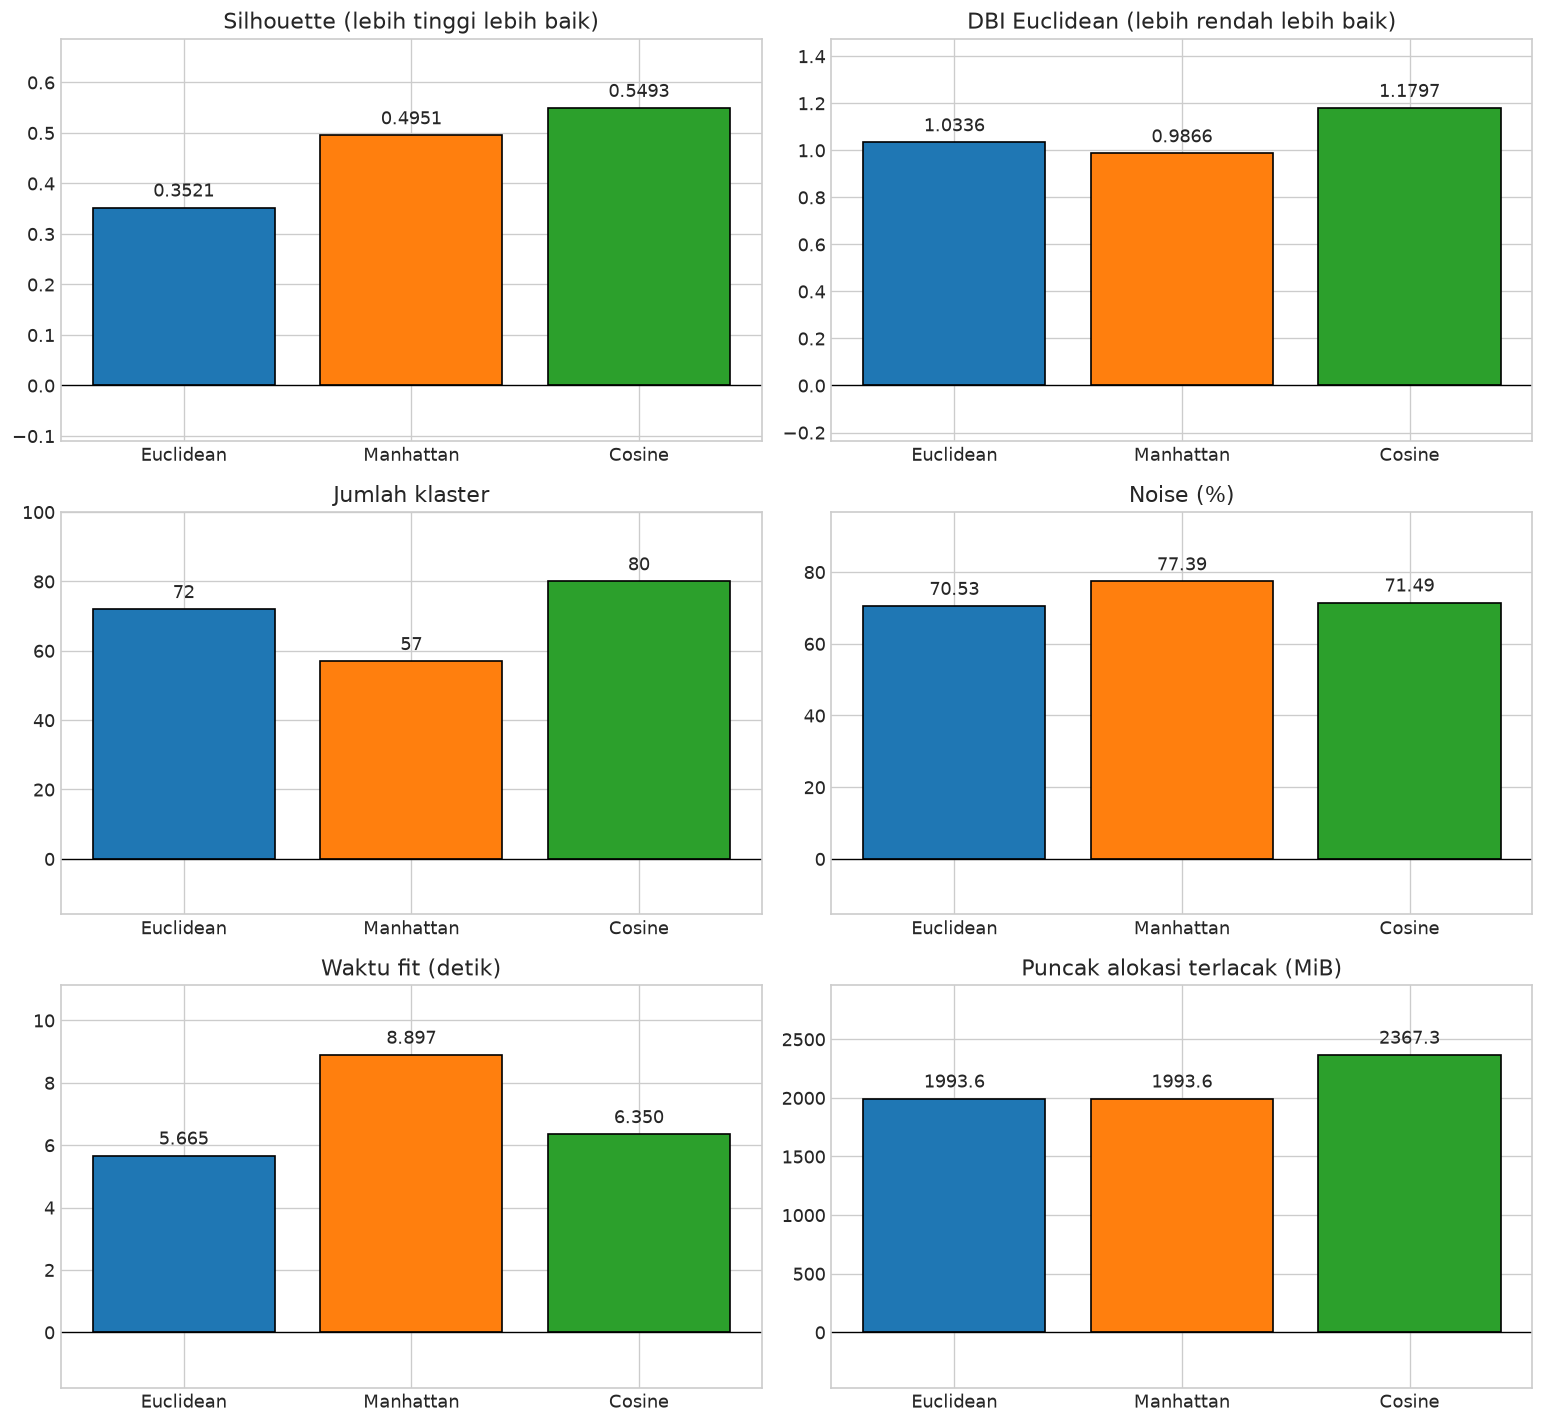

In [ ]:
# =======================================================================
# 11. VISUALISASI EVALUASI & KINERJA
# =======================================================================
panels = [('Silhouette Score', 'Silhouette (lebih tinggi lebih baik)', '{:.4f}'),
          ('DBI (Euclidean)', 'DBI Euclidean (lebih rendah lebih baik)', '{:.4f}')]
if STUDY_NAME == 'perbandingan':
    panels += [('Jumlah Klaster', 'Jumlah klaster', '{:.0f}'), ('Noise (%)', 'Noise (%)', '{:.2f}'),
               ('Waktu Eksekusi (detik)', 'Waktu fit (detik)', '{:.3f}'),
               ('Penggunaan Memori (MiB)', 'Puncak alokasi terlacak (MiB)', '{:.1f}')]
fig, axes = plt.subplots(len(panels) // 2, 2, figsize=(13, 4 * len(panels) // 2), squeeze=False)
for ax, (column, title, fmt) in zip(axes.ravel(), panels):
    values = comparison_df[column].to_numpy(dtype=float)
    bars = ax.bar(comparison_df['Distance Metric'], np.nan_to_num(values),
        color=['tab:blue', 'tab:orange', 'tab:green'][:len(values)], edgecolor='black')
    finite = values[np.isfinite(values)]
    extent = max(float(np.max(np.abs(finite))) if len(finite) else 1, 1e-5)
    ax.set_ylim(min(0, float(finite.min()) if len(finite) else 0) - 0.2 * extent,
                max(0, float(finite.max()) if len(finite) else 0) + 0.25 * extent)
    for bar, value in zip(bars, values):
        ax.annotate(fmt.format(value) if np.isfinite(value) else 'N/A',
            (bar.get_x() + bar.get_width() / 2, value if np.isfinite(value) else 0),
            xytext=(0, 4 if not np.isfinite(value) or value >= 0 else -4), textcoords='offset points',
            ha='center', va='bottom' if not np.isfinite(value) or value >= 0 else 'top')
    ax.set_title(title)
    ax.axhline(0, color='black', lw=0.8)
plt.tight_layout()
plt.savefig(output_dir / 'evaluasi_dan_kinerja.png', bbox_inches='tight')
plt.show()


In [ ]:
# =======================================================================
# 12. RINGKASAN & SIMPAN HASIL
# =======================================================================
for _, row in comparison_df.iterrows():
    sil = f"{row['Silhouette Score']:.4f}" if np.isfinite(row['Silhouette Score']) else 'N/A'
    dbi = f"{row['DBI (Euclidean)']:.4f}" if np.isfinite(row['DBI (Euclidean)']) else 'N/A'
    print(f"{row['Distance Metric']}: {int(row['Jumlah Klaster'])} klaster, noise {row['Noise (%)']:.2f}%, Silhouette {sil}, DBI {dbi}.")
print('Baca skor bersama persentase noise: evaluasi hanya memakai titik non-noise.')
print('PCA adalah visualisasi. Model tetap memakai semua fitur setelah StandardScaler.')
print('Semua metrik memakai parameter bersama yang ditetapkan sebelum fit.')

comparison_df.to_csv(output_dir / 'perbandingan.csv', index=False)
scale_df.to_csv(output_dir / 'uji_skala.csv', index=False)
cut_df.to_csv(output_dir / 'cut_distance.csv', index=False)
pair_distance_df.to_csv(output_dir / 'distance_node_contoh.csv', index=False)
row_results = pd.DataFrame({'Row': np.arange(len(df)), 'url': urls, 'status': y_true})
for metric, model in models_by_metric.items():
    row_results[f'{metric}_cluster'] = model.labels_
    row_results[f'{metric}_membership_strength'] = model.probabilities_
    feature_tables[metric].to_csv(output_dir / f'{metric}_bukti_distance_per_fitur.csv', index=False)
    core_tables[metric].to_csv(output_dir / f'{metric}_core_distance.csv', index=False)
    reachability_tables[metric].to_csv(output_dir / f'{metric}_mutual_reachability.csv', index=False)
row_results.to_csv(output_dir / 'hasil_per_url.csv', index=False)
metadata = {'n_rows': len(df), 'n_features': X_scaled.shape[1], 'metrics': DISTANCE_METRICS,
    'min_cluster_size': MIN_CLUSTER_SIZE, 'min_samples': MIN_SAMPLES,
    'algorithm': 'generic', 'silhouette_population': 'all non-noise rows',
    'dbi_geometry': 'euclidean', 'comparison_parameters': [MIN_CLUSTER_SIZE, MIN_SAMPLES],
    'hdbscan_version': version('hdbscan'), 'sklearn_version': version('scikit-learn')}
(output_dir / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Hasil:', output_dir.resolve())


Euclidean: 72 klaster, noise 70.53%, Silhouette 0.3521, DBI 1.0336.
Manhattan: 57 klaster, noise 77.39%, Silhouette 0.4951, DBI 0.9866.
Cosine: 80 klaster, noise 71.49%, Silhouette 0.5493, DBI 1.1797.
Baca skor bersama persentase noise: evaluasi hanya memakai titik non-noise.
PCA adalah visualisasi. Model tetap memakai semua fitur setelah StandardScaler.
Semua metrik memakai parameter bersama yang ditetapkan sebelum fit.
Hasil: /Users/jergal/Downloads/hdscan/hasil_hdbscan/perbandingan


### Pembahasan hasil

Baca jumlah klaster, persentase noise, Silhouette, dan DBI bersama-sama. Skor non-noise yang tinggi dapat hanya mencakup sebagian kecil dataset. Klaster tidak otomatis sama dengan kelas phishing atau legitimate; `status` tidak menjadi masukan atau kriteria pemilihan parameter.

Gunakan grafik skala untuk melihat perubahan pola klaster, lalu periksa bagaimana cut_distance memengaruhi jumlah klaster dan noise. Tabel perbandingan membantu membaca perbedaan hasil ketiga metrik pada parameter yang sama.